In [2]:
using CSV, DataFrames
using Plots
using LinearAlgebra
using Statistics
using LaTeXStrings

In [3]:
binder_df = CSV.read("simulation_results/metropolis_binder_data.csv", DataFrame);

binder_df.chi = binder_df.L.^2 ./ binder_df.T .* (binder_df.m2_mean .- binder_df.m_mean.^2);
binder_df.chi_abs = binder_df.L.^2 ./ binder_df.T .* (binder_df.m2_mean .- binder_df.mAbs_mean.^2);

binder_df

Row,L,T,m2_mean,m4_mean,m_mean,mAbs_mean,U,chi,chi_abs
,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,16,2.2,0.650903,0.458607,0.0677482,0.793802,0.639183,75.2073,2.41814
2,16,2.205,0.646089,0.452806,0.0887961,0.790562,0.638418,74.0954,2.44971
3,16,2.21,0.636528,0.442046,0.0670737,0.78365,0.636326,73.2124,2.59709
4,16,2.215,0.631575,0.436281,0.0802816,0.78011,0.635418,72.2498,2.65867
5,16,2.22,0.622195,0.4268,0.00903442,0.772539,0.632507,71.7392,2.9266
6,16,2.225,0.61592,0.419604,0.0771837,0.768113,0.631303,70.18,2.98263
7,16,2.23,0.608373,0.410762,0.066661,0.763044,0.630063,69.33,3.00046
8,16,2.235,0.599304,0.401911,1.21257e-5,0.755436,0.626995,68.6451,3.27816
9,16,2.24,0.590845,0.392964,-0.0463871,0.749125,0.624781,67.2793,3.38932


Definimos la temperatura reducida como
$$t = \frac{T-T_c}{T_c}$$

La hipótesis del _finite-size scaling_ es que para un observable $\mathcal O$ podemos escribir
$$\mathcal O(L, T) = L^{\rho} f_\mathcal{O}(tL^{1/\nu})$$
Esto se puede demostrar para observables que presentan singularidades usando argumentos del grupo de renormalización.

Esto es equivalente a escribir
$$\mathcal O(L, T) = L^{\rho} \tilde f_\mathcal{O}((T-T_c)L^{1/\nu})$$
donde $\tilde f_\mathcal{O}(x) = f_\mathcal{O}(x/T_c)$.

En particular, para el $k$-ésimo momento de la magnetización podemos escribir

$$\langle m^k\rangle = L^{-k\beta/\nu} f_k(t L^{1/\nu})$$

La definición del **cumulante de Binder** es
$$U = 1 - \frac{\langle m^4\rangle}{3\langle m^2\rangle^2}$$
Por lo que si reemplazamos con las funciones de escalamiento tenemos
$$U = 1 - \frac{L^{-4\beta/\nu} f_4(t L^{1/\nu})}{3(L^{-2\beta/\nu} f_2(t L^{1/\nu}))^2}$$
$$\implies U = 1 - \frac{ f_4(t L^{1/\nu})}{3(f_2(t L^{1/\nu}))^2}$$
Por lo tanto podemos definir una nueva función de escalamiento $f_U$
$$U(L, T) = f_U(t L^{1/\nu})$$

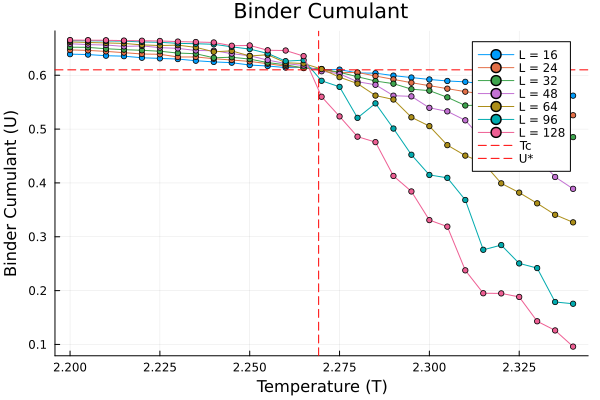

In [4]:
p = plot(
    title = "Binder Cumulant",
    xlabel = "Temperature (T)",
    ylabel = "Binder Cumulant (U)",
    legend = :topright,
    linewidth = 8,
    grid = true,
)

for L in [16, 24, 32, 48, 64, 96, 128]
    df_L = binder_df[binder_df.L .== L, :]
    sort!(df_L, :T)

    plot!(p, df_L.T, df_L.U, label = "L = $L", marker=:circ, markersize=3)
end

Tc = 2.269185

vline!(
    p,
    [Tc],
    label = "Tc",
    color = :red,
    linestyle = :dash,
    linewidth = 1
)

U_t = 0.61 #valor en que debería ocurrir el cruce

hline!(
    p,
    [U_t],
    label = "U*",
    color =:red,
    linestyle = :dash,
    linewidth = 1
)

p

Como
$$U(L, T) = \tilde f_U((T-T_c) L^{1/\nu})$$
En $T_c$ tenemos
$$U(L, T_c) = \tilde f_U(0)$$

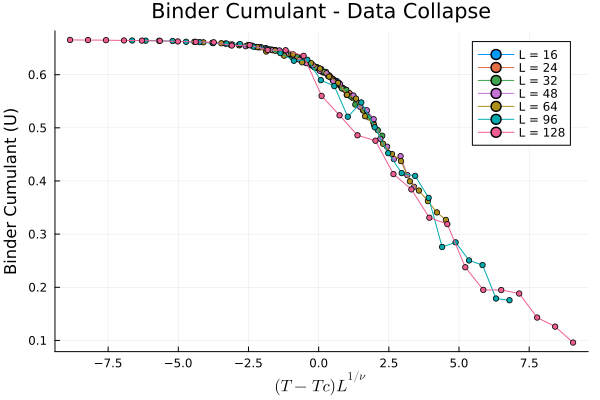

In [9]:
p = plot(
    title = "Binder Cumulant - Data Collapse",
    xlabel = L"$(T - Tc)L^{1/\nu}$",
    ylabel = "Binder Cumulant (U)",
    legend = :topright,
    linewidth = 2,
    grid = true,
)

nu = 1
Tc = 2.269185

for L in [16, 24, 32, 48, 64, 96, 128]
    df_L = binder_df[binder_df.L .== L, :]
    sort!(df_L, :T)

    x = (df_L.T .- Tc) .* L^(1/nu)

    plot!(p, x, df_L.U, label = "L = $L", marker=:circle, markersize=3)
end
p

Tenemos que
$$U(L, T)= \tilde {f_U}((T-T_c)L^{1/\nu})$$
luego, derivamos
$$\frac{\partial U}{\partial T}=L^{1/\nu}\tilde {f_U}'((T-T_c)L^{1/\nu})$$
Evaluamos en $T = T_c$
$$\left.\frac{\partial U}{\partial T}\right|_{T_c} \propto L^{1/\nu}$$
Finalmente tomando logaritmo
$$\log\left|\left.\frac{\partial U}{\partial T}\right|_{T_c}\right| \approx \frac{1}{\nu} \log(L)+C$$

Valor real de nu: 1
Valor estimado de nu: 0.8395982579603436
Error relativo: 0.16


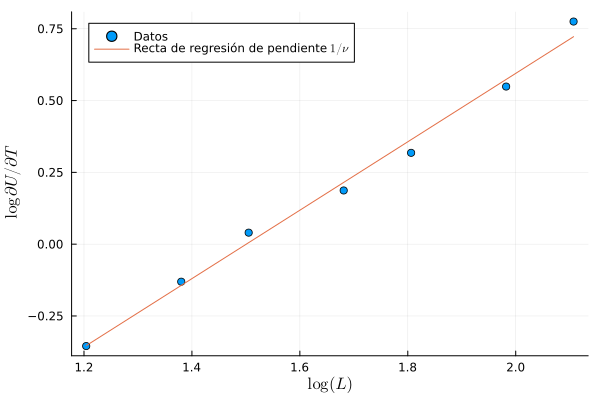

In [14]:
b_Ls = []
Ls = [16, 24, 32, 48, 64, 96, 128]

delta = 0.02
Tc = 2.269185

# Obtenemos la pendiente de la regresión para cada L, esta aproxima la derivada de U
for L in Ls
    filtered_df = binder_df[(binder_df.L .== L) .& (Tc - delta .<= binder_df.T .<= Tc + delta) , :]

    T = filtered_df.T
    U = filtered_df.U 

    X = hcat(ones(length(T)), T)
    a_L, b_L = X \ U
    push!(b_Ls, b_L)
end


ps = []

x = log10.(Ls)
y = log10.(abs.(b_Ls)) # dU/dT

X = hcat(ones(length(x)), x)
c, p = X \ y
nu = 1
nu_hat = 1 / p
err_rel = abs((nu - nu_hat)/nu)

println("Valor real de nu: ", nu)
println("Valor estimado de nu: ", nu_hat)
println("Error relativo: ", round(err_rel, digits=3))

scatter(x, y, xlabel=L"$\log(L)$", ylabel=L"$\log\partial U/\partial T$", label="Datos")
plot!(x, p .* x .+ c, label=L"Recta de regresión de pendiente $1/\nu$")


Ahora tenemos
$$\langle|m_L|\rangle(T)= L^{-\beta/\nu} f_m\left((T-T_c)L^{1/\nu}\right)$$
$$\log\langle|m_L|\rangle(T_c)=\frac{-\beta}{\nu}\log(L)+C$$


Valor real de beta: 0.125
Valor estimación de beta: 0.14354962405589444
Error relativo: 0.148


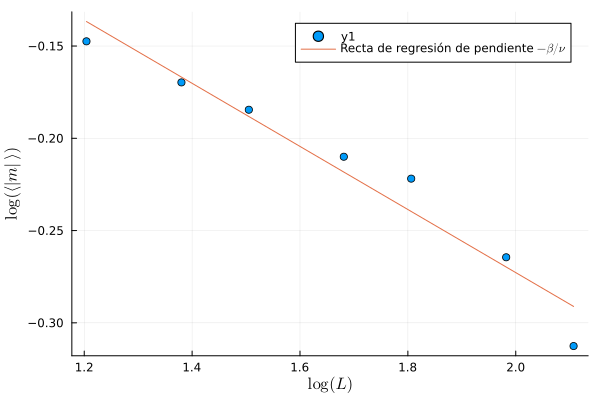

In [10]:
Ls = [16, 24, 32, 48, 64, 96, 128]
m_abs = binder_df[binder_df.T .== 2.27, :].mAbs_mean

x = log10.(Ls)
y = log10.(m_abs)

X = hcat(ones(length(x)), x)
c, p = X \ y

beta = 1/8
beta_hat = -p * nu_hat
err_rel = abs((beta - beta_hat)/beta)

println("Valor real de beta: ", beta)
println("Valor estimación de beta: ", beta_hat)
println("Error relativo: ", round(err_rel, digits=3))

scatter(x, y, xlabel=L"\log(L)", ylabel=L"\log(\langle |m|\rangle)")
plot!(x, x .* p .+ c, label=L"Recta de regresión de pendiente $-\beta/\nu$")

$$\chi_L(T)= L^{\gamma/\nu} f_\chi\left((T-T_c)L^{1/\nu}\right)$$
$$\chi_L(T_c)=\frac{\gamma}{\nu}\log(L)+C$$

gamma real: 1.75
Estimación de gamma: 1.6322442817594451
Error relativo: 0.067


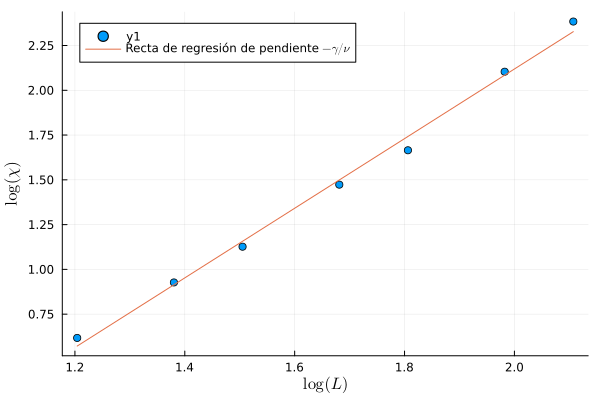

In [12]:
Ls = [16, 24, 32, 48, 64, 96, 128]
chis = binder_df[binder_df.T .== 2.27, :].chi_abs

x = log10.(Ls)
y = log10.(chis)

X = hcat(ones(length(x)), x)
c, p = X \ y


gamma_hat = p * nu_hat
gamma = 7/4
err_rel = abs((gamma - gamma_hat)/gamma)

println("gamma real: ", gamma)
println("Estimación de gamma: ", gamma_hat)
println("Error relativo: ", round(err_rel, digits=3))

scatter(x, y, xlabel=L"\log(L)", ylabel=L"\log(\chi)")
plot!(x, x .* p .+ c, label=L"Recta de regresión de pendiente $-\gamma/\nu$")

## Referencias
- https://arxiv.org/pdf/0905.1629
- https://alps.comp-phys.org/tutorials/mcs/mc07/
- https://arxiv.org/pdf/cond-mat/0402036
- https://arxiv.org/pdf/cond-mat/0102515